In [1]:
# ============ 셀 1: 설정 (E2: AdamW ρ 스윕 + E1과 같은 평가) ============
import os, json, time, math, random, glob, shutil, copy
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.attention import sdpa_kernel, SDPBackend

assert torch.cuda.is_available(), "GPU가 꺼져 있어요. Settings → Accelerator → GPU T4 로 바꾸세요."
DEV = 'cuda'
OUT  = '/kaggle/working/exp_e2'
DATA = '/tmp/llm_data'
os.makedirs(OUT, exist_ok=True); os.makedirs(DATA, exist_ok=True)

CFG = dict(
    seed=0, ctx=256, vocab=50304, d_model=512, n_layer=6, n_head=8, grad_clip=1.0,
    muon_momentum=0.95, ns_steps=5,
    pre_epochs=10, pre_bs=32, pre_wd=0.1, warmup_frac=0.02, decay_frac=0.2,
    new_rhos=[0.02, 0.1, 0.2],
    timing_steps=300,
    ft_lr_div=[10, 3], ft_steps=1000, ft_bs=32, ft_wd=0.1, ft_warmup=50, ft_seeds=[0, 1, 2], ft_eval_every=100,
    code_files=10000, code_max_chars=20000, eval_seqs=400, eval_bs=32,
    blimp_per_task=200, quant_bits=[8, 4], noise_gammas=[0.01, 0.02, 0.05], noise_reps=3,
    hutch_samples=20, lam_batches=3, hvp_iters=20, curv_batches=2, cka_seqs=64, cka_tokens=4096,
)
json.dump(CFG, open(f'{OUT}/config.json', 'w'), indent=2)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def find_input(folder, name):
    hits = glob.glob(f'/kaggle/input/**/{folder}/{name}', recursive=True)
    assert hits, f"{folder}/{name}을 못 찾았어요. Add Input에서 해당 노트북을 추가했는지 확인하세요."
    return hits[0]

print('GPU :', torch.cuda.get_device_name(0), '| torch', torch.__version__)
for f in ['exp_llm_adamw/pre_shared.pt', 'exp_llm_adamw/pre_off.pt', 'exp_llm_adamw/pre_sam.pt',
          'exp_llm_adamw/lr_sweep.json', 'exp_e1/ft_curves.json', 'exp_e1/pretrain_metrics.json']:
    print('  입력 확인:', f, '→', '있음' if glob.glob(f'/kaggle/input/**/{f}', recursive=True) else '없음 ← Add Input 확인')

GPU : Tesla T4 | torch 2.11.0+cu128
  입력 확인: exp_llm_adamw/pre_shared.pt → 있음
  입력 확인: exp_llm_adamw/pre_off.pt → 있음
  입력 확인: exp_llm_adamw/pre_sam.pt → 있음
  입력 확인: exp_llm_adamw/lr_sweep.json → 있음
  입력 확인: exp_e1/ft_curves.json → 있음
  입력 확인: exp_e1/pretrain_metrics.json → 있음


In [2]:
# ============ 셀 2: BabyLM + 파이썬 코드 + BLiMP ============
from transformers import AutoTokenizer
from datasets import load_dataset
tok = AutoTokenizer.from_pretrained('gpt2'); tok.model_max_length = int(1e9)
EOS = tok.eos_token_id

def encode_texts(texts, bs=256):
    parts = []
    for i in range(0, len(texts), bs):
        for ids in tok(texts[i:i + bs])['input_ids']:
            parts.append(np.array(ids + [EOS], dtype=np.uint16))
    return np.concatenate(parts)

def chunk_lines(text, n=200):
    lines = text.split('\n')
    return ['\n'.join(lines[i:i + n]) for i in range(0, len(lines), n)]

if not os.path.exists(f'{DATA}/babylm_val.npy'):
    try:
        from huggingface_hub import snapshot_download
        root = snapshot_download('cambridge-climb/BabyLM', repo_type='dataset', allow_patterns=['10M/*', 'dev/*'])
        tr_files = sorted(f for f in glob.glob(f'{root}/10M/*') if os.path.isfile(f))
        dv_files = sorted(f for f in glob.glob(f'{root}/dev/*') if os.path.isfile(f))
        assert tr_files and dv_files, '파일 없음'
        tr_texts, dv_texts = [], []
        for f in tr_files: tr_texts += chunk_lines(open(f, encoding='utf-8', errors='ignore').read())
        for f in dv_files: dv_texts += chunk_lines(open(f, encoding='utf-8', errors='ignore').read()[:500_000])
    except Exception as e:
        print('2023판 다운로드 실패 → 2026판으로 대체:', repr(e)[:120])
        ds = load_dataset('BabyLM-community/BabyLM-2026-Strict-Small', split='train')
        col = [c for c, t in ds.features.items() if getattr(t, 'dtype', None) == 'string'][0]
        lines = [t for t in ds[col] if t and t.strip()]
        idx = np.random.RandomState(0).permutation(len(lines)); nv = len(lines) // 20
        dv_lines = [lines[i] for i in idx[:nv]]; tr_lines = [lines[i] for i in idx[nv:]]
        tr_texts = ['\n'.join(tr_lines[i:i + 200]) for i in range(0, len(tr_lines), 200)]
        dv_texts = ['\n'.join(dv_lines[i:i + 200]) for i in range(0, len(dv_lines), 200)]
    tr = encode_texts(tr_texts); dv = encode_texts(dv_texts)
    np.save(f'{DATA}/babylm_train.npy', tr); np.save(f'{DATA}/babylm_val.npy', dv)
    print(f'BabyLM 토큰: train {len(tr)/1e6:.1f}M, val {len(dv)/1e6:.1f}M   (기존: 15.7M / 0.8M)')

if not os.path.exists(f'{DATA}/code_val.npy'):
    try:
        ds = load_dataset('bigcode/the-stack-smol', data_dir='data/python', split='train')
    except Exception as e:
        print('the-stack-smol 실패 → codeparrot으로 대체:', repr(e)[:120])
        ds = load_dataset('codeparrot/codeparrot-clean-valid', split='train')
    n = min(CFG['code_files'], len(ds))
    ds = ds.shuffle(seed=0).select(range(n))
    files = [c[:CFG['code_max_chars']] for c in ds['content']]
    nv = n // 10
    cv = encode_texts(files[:nv]); ct = encode_texts(files[nv:])
    np.save(f'{DATA}/code_train.npy', ct); np.save(f'{DATA}/code_val.npy', cv)
    print(f'코드 토큰: train {len(ct)/1e6:.1f}M, val {len(cv)/1e6:.1f}M   (기존: 26.9M / 3.0M)')

if not os.path.exists(f'{DATA}/blimp.json'):
    from datasets import get_dataset_config_names
    for name in ['nyu-mll/blimp', 'blimp']:
        try:
            cfgs = get_dataset_config_names(name); break
        except Exception as e:
            print(f'{name} 설정 목록 실패:', repr(e)[:120])
    rng = np.random.RandomState(0); rows = []
    for c in cfgs:
        ds = load_dataset(name, c, split='train')
        for i in rng.choice(len(ds), min(CFG['blimp_per_task'], len(ds)), replace=False):
            r = ds[int(i)]
            rows.append(dict(task=c, field=r.get('field', 'unknown'), good=r['sentence_good'], bad=r['sentence_bad']))
    json.dump(rows, open(f'{DATA}/blimp.json', 'w'))
BLIMP = json.load(open(f'{DATA}/blimp.json'))
print(f'BLiMP: {len(BLIMP)}쌍, 현상 {len(set(r["task"] for r in BLIMP))}개')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

wh_vs_that_with_gap_long_distance/train-(…): reconstructing file:   0%|          |  0.00B / 84.1kB            

wh_vs_that_with_gap_long_distance/train-(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

BLiMP: 13400쌍, 현상 67개


In [3]:
# ============ 셀 3: 모델, Muon, 파인튜닝, 평가 지표 함수 ============
def load_tokens(name):
    return torch.from_numpy(np.load(f'{DATA}/{name}.npy').astype(np.int64)).to(DEV)

TR_BABY, VA_BABY = load_tokens('babylm_train'), load_tokens('babylm_val')
TR_CODE, VA_CODE = load_tokens('code_train'), load_tokens('code_val')

class Stream:
    def __init__(self, tokens, bs, ctx=CFG['ctx']):
        n = (len(tokens) - 1) // ctx
        self.chunks = tokens[:n * ctx + 1].unfold(0, ctx + 1, ctx)
        self.n, self.bs, self.spe = n, bs, n // bs
        self._key = None
    def batch(self, step, seed):
        ep, i = divmod(step, self.spe)
        if self._key != (seed, ep):
            g = torch.Generator().manual_seed(seed * 100003 + ep)
            self._perm = torch.randperm(self.n, generator=g).to(DEV); self._key = (seed, ep)
        b = self.chunks[self._perm[i * self.bs:(i + 1) * self.bs]]
        return b[:, :-1], b[:, 1:]

def make_eval(tokens, n, seed, ctx=CFG['ctx']):
    starts = np.random.RandomState(seed).randint(0, len(tokens) - ctx - 1, size=n)
    idx = torch.from_numpy(starts).to(DEV)[:, None] + torch.arange(ctx + 1, device=DEV)
    b = tokens[idx]
    return b[:, :-1], b[:, 1:]

EV_BABY = make_eval(VA_BABY, CFG['eval_seqs'], seed=11)
EV_CODE = make_eval(VA_CODE, CFG['eval_seqs'], seed=12)

class Block(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.h = h
        self.ln1 = nn.LayerNorm(d); self.qkv = nn.Linear(d, 3 * d); self.proj = nn.Linear(d, d)
        self.ln2 = nn.LayerNorm(d); self.fc = nn.Linear(d, 4 * d); self.fc2 = nn.Linear(4 * d, d)
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(C, dim=2)
        q, k, v = [t.view(B, T, self.h, C // self.h).transpose(1, 2) for t in (q, k, v)]
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        x = x + self.proj(y.transpose(1, 2).contiguous().view(B, T, C))
        return x + self.fc2(F.gelu(self.fc(self.ln2(x))))

class GPT(nn.Module):
    def __init__(self, V=CFG['vocab'], d=CFG['d_model'], L=CFG['n_layer'], h=CFG['n_head'], T=CFG['ctx']):
        super().__init__()
        self.wte = nn.Embedding(V, d); self.wpe = nn.Embedding(T, d)
        self.blocks = nn.ModuleList([Block(d, h) for _ in range(L)])
        self.lnf = nn.LayerNorm(d)
    def forward(self, idx, targets=None, return_hidden=False):
        x = self.wte(idx) + self.wpe(torch.arange(idx.shape[1], device=idx.device))
        hs = [x] if return_hidden else None
        for b in self.blocks:
            x = b(x)
            if return_hidden: hs.append(x)
        logits = F.linear(self.lnf(x), self.wte.weight)
        if return_hidden: return logits, hs
        if targets is None: return logits
        return F.cross_entropy(logits.view(-1, logits.size(-1)), targets.reshape(-1))

def make_model():
    return GPT().to(DEV)

def load_model(sd):
    m = make_model(); m.load_state_dict(sd); return m

def newton_schulz5(G, steps):
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G.float(); X = X / (X.norm() + 1e-7)
    tr = X.size(0) > X.size(1)
    if tr: X = X.T
    for _ in range(steps):
        A = X @ X.T; B = b * A + c * (A @ A); X = a * X + B @ X
    return X.T if tr else X

class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr=0.02, momentum=0.95, nesterov=True, ns_steps=5):
        super().__init__(params, dict(lr=lr, momentum=momentum, nesterov=nesterov, ns_steps=ns_steps))
    @torch.no_grad()
    def step(self, closure=None):
        for grp in self.param_groups:
            for p in grp['params']:
                if p.grad is None: continue
                st = self.state[p]
                if 'buf' not in st: st['buf'] = torch.zeros_like(p.grad)
                buf = st['buf']; buf.mul_(grp['momentum']).add_(p.grad)
                u = p.grad.add(buf, alpha=grp['momentum']) if grp['nesterov'] else buf
                u = newton_schulz5(u, grp['ns_steps'])
                u *= max(1.0, p.size(0) / p.size(1)) ** 0.5
                p.add_(u.to(p.dtype), alpha=-grp['lr'])

def make_muon_opts(model, muon_lr, adam_lr, wd):
    hidden = [p for p in model.blocks.parameters() if p.ndim == 2]
    hid = {id(p) for p in hidden}
    rest = [p for p in model.parameters() if id(p) not in hid]
    muon = Muon(hidden, lr=muon_lr, momentum=CFG['muon_momentum'], ns_steps=CFG['ns_steps'])
    adam = torch.optim.AdamW([{'params': [p for p in rest if p.ndim >= 2], 'weight_decay': wd},
                              {'params': [p for p in rest if p.ndim < 2], 'weight_decay': 0.0}],
                             lr=adam_lr, betas=(0.9, 0.95), eps=1e-8)
    for o, lr in ((muon, muon_lr), (adam, adam_lr)):
        for g in o.param_groups: g['base_lr'] = lr
    return [muon, adam]

def cos_fn(total, warm):
    def f(s):
        if s < warm: return (s + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
    return f

def train_step(model, opts, scaler, x, y):
    with torch.autocast('cuda', dtype=torch.float16):
        loss = model(x, y)
    model.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    for o in opts: scaler.unscale_(o)
    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
    for o in opts: scaler.step(o)
    scaler.update()

@torch.no_grad()
def eval_loss(model, ev):
    model.eval(); X, Y = ev; tot = 0.0; bs = CFG['eval_bs']
    for i in range(0, len(X), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            tot += model(X[i:i + bs], Y[i:i + bs]).float().item() * len(X[i:i + bs])
    model.train()
    return tot / len(X)

@torch.no_grad()
def token_acc(model, ev):
    model.eval(); X, Y = ev; hit = 0; n = 0; bs = CFG['eval_bs']
    for i in range(0, len(X), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            pred = model(X[i:i + bs]).argmax(-1)
        hit += (pred == Y[i:i + bs]).sum().item(); n += Y[i:i + bs].numel()
    model.train()
    return hit / n

_ids = lambda s: [EOS] + tok(s)['input_ids']
BL_GOOD = [_ids(r['good']) for r in BLIMP]; BL_BAD = [_ids(r['bad']) for r in BLIMP]
BL_FIELD = np.array([r['field'] for r in BLIMP])

@torch.no_grad()
def sent_logprob(model, seqs, bs=128):
    model.eval(); out = np.zeros(len(seqs)); order = np.argsort([len(s) for s in seqs])
    for i in range(0, len(seqs), bs):
        idx = order[i:i + bs]; L = max(len(seqs[j]) for j in idx)
        X = torch.full((len(idx), L), EOS, dtype=torch.long, device=DEV); M = torch.zeros((len(idx), L), device=DEV)
        for r, j in enumerate(idx):
            X[r, :len(seqs[j])] = torch.tensor(seqs[j], device=DEV); M[r, :len(seqs[j])] = 1
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(X[:, :-1])
        lp = torch.log_softmax(logits.float(), -1).gather(-1, X[:, 1:, None]).squeeze(-1) * M[:, 1:]
        out[idx] = lp.sum(1).cpu().numpy()
    model.train()
    return out

def blimp(model):
    ok = sent_logprob(model, BL_GOOD) > sent_logprob(model, BL_BAD)
    return dict(acc=float(ok.mean()), **{f'acc_{f}': float(ok[BL_FIELD == f].mean()) for f in sorted(set(BL_FIELD))})

@torch.no_grad()
def quantized(model, bits):
    m = copy.deepcopy(model); qmax = 2 ** (bits - 1) - 1
    for p in m.parameters():
        if p.ndim == 2:
            s = p.abs().amax(dim=1, keepdim=True).clamp(min=1e-8) / qmax
            p.copy_((p / s).round().clamp(-qmax - 1, qmax) * s)
    return m

def quant_metrics(model, base_baby, base_code):
    out = {}
    for b in CFG['quant_bits']:
        q = quantized(model, b)
        out[f'int{b}_baby_inc'] = eval_loss(q, EV_BABY) - base_baby
        out[f'int{b}_code_inc'] = eval_loss(q, EV_CODE) - base_code
        del q
    torch.cuda.empty_cache()
    return out

@torch.no_grad()
def noise_metrics(model, base_baby):
    mats = [p for p in model.parameters() if p.ndim == 2]; out = {}
    for g in CFG['noise_gammas']:
        vals = []
        for r in range(CFG['noise_reps']):
            gen = torch.Generator(device=DEV).manual_seed(1000 + r)
            backup = [p.detach().clone() for p in mats]
            for p in mats:
                p.add_(torch.randn(p.shape, generator=gen, device=DEV) * g * p.norm() / math.sqrt(p.numel()))
            vals.append(eval_loss(model, EV_BABY) - base_baby)
            for p, b in zip(mats, backup): p.copy_(b)
        out[f'noise{g:g}_inc'] = float(np.mean(vals))
    return out

def lambda_max(model, batch, iters):
    model.eval(); x, y = batch; params = list(model.parameters())
    with sdpa_kernel(SDPBackend.MATH):
        loss = model(x, y)
        grads = torch.autograd.grad(loss, params, create_graph=True)
        v = [torch.randn_like(p) for p in params]
        nrm = torch.sqrt(sum((a * a).sum() for a in v)); v = [a / nrm for a in v]
        lam = 0.0
        for _ in range(iters):
            Hv = torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True)
            lam = sum((h * a).sum() for h, a in zip(Hv, v)).item()
            nrm = torch.sqrt(sum((h * h).sum() for h in Hv)); v = [h.detach() / nrm for h in Hv]
    del grads
    return lam

def hutchinson_trace(model, batches, n):
    model.eval(); params = list(model.parameters()); vals = []
    with sdpa_kernel(SDPBackend.MATH):
        for k in range(n):
            x, y = batches[k % len(batches)]
            loss = model(x, y)
            grads = torch.autograd.grad(loss, params, create_graph=True)
            v = [torch.randint_like(p, 2) * 2 - 1 for p in params]
            Hv = torch.autograd.grad(grads, params, grad_outputs=v)
            vals.append(sum((h * a).sum() for h, a in zip(Hv, v)).item())
            del grads, Hv
    return float(np.mean(vals)), float(np.std(vals) / math.sqrt(n))

@torch.no_grad()
def rank_metrics(model):
    er, sr = [], []
    for p in model.blocks.parameters():
        if p.ndim == 2:
            s = torch.linalg.svdvals(p.float()); q = s / s.sum()
            er.append((torch.exp(-(q * torch.log(q + 1e-12)).sum()) / len(s)).item())
            sr.append((s.pow(2).sum() / s[0] ** 2).item())
    return dict(erank_norm=float(np.mean(er)), stable_rank=float(np.mean(sr)))

def dir_curvature(sd_pre, sd_post, batches):
    m = load_model(sd_pre); m.eval(); names = [n for n, _ in m.named_parameters()]
    params = [p for _, p in m.named_parameters()]
    delta = [(sd_post[n].float() - p.detach().float()) for n, p in zip(names, params)]
    dn2 = sum((d * d).sum() for d in delta).item()
    mp = load_model(sd_post); mp.eval(); g1, q2, act = [], [], []
    with sdpa_kernel(SDPBackend.MATH):
        for x, y in batches:
            loss = m(x, y)
            grads = torch.autograd.grad(loss, params, create_graph=True)
            gd = sum((g * d).sum() for g, d in zip(grads, delta))
            Hd = torch.autograd.grad(gd, params)
            dHd = sum((h * d).sum() for h, d in zip(Hd, delta)).item()
            with torch.no_grad():
                act.append((mp(x, y) - loss).item())
            g1.append(gd.item()); q2.append(dHd)
            del grads, Hd
    del m, mp; torch.cuda.empty_cache()
    return dict(dir_curv=float(np.mean(q2)) / dn2, first_order=float(np.mean(g1)),
                second_order=0.5 * float(np.mean(q2)), quad_pred=float(np.mean(g1)) + 0.5 * float(np.mean(q2)),
                actual_inc=float(np.mean(act)))

CKA_X = EV_BABY[0][:CFG['cka_seqs']]
CKA_IDX = torch.from_numpy(np.random.RandomState(7).choice(CKA_X.numel(), CFG['cka_tokens'], replace=False)).to(DEV)

@torch.no_grad()
def layer_feats(model):
    model.eval(); outs = None
    for i in range(0, len(CKA_X), 16):
        with torch.autocast('cuda', dtype=torch.float16):
            _, hs = model(CKA_X[i:i + 16], return_hidden=True)
        hs = [h.float().reshape(-1, h.size(-1)) for h in hs]
        outs = hs if outs is None else [torch.cat([a, b]) for a, b in zip(outs, hs)]
    return [h[CKA_IDX].double() for h in outs]

def linear_cka(A, B):
    A = A - A.mean(0); B = B - B.mean(0)
    return ((A.T @ B).norm() ** 2 / ((A.T @ A).norm() * (B.T @ B).norm())).item()

def delta_rel(sd_a, sd_b):
    num = den = 0.0
    for k, v in sd_a.items():
        if not v.is_floating_point(): continue
        num += (sd_b[k].float() - v.float()).pow(2).sum().item(); den += v.float().pow(2).sum().item()
    return math.sqrt(num / den)

def baby_at(curve, target):
    for a, b in zip(curve, curve[1:]):
        if b['code'] <= target:
            t = 1.0 if a['code'] == b['code'] else min(max((a['code'] - target) / (a['code'] - b['code']), 0), 1)
            return a['baby'] + t * (b['baby'] - a['baby'])
    return float('nan')

tr_stream = Stream(TR_BABY, 32)
SHARP_BATCHES = [tuple(t[:16] for t in tr_stream.batch(s, seed=999)) for s in range(max(CFG['lam_batches'], 4))]
CURV_BATCHES = SHARP_BATCHES[:CFG['curv_batches']]
print('도구 준비 완료')

도구 준비 완료


In [4]:
# ============ 셀 3b: AdamW + 유클리드 SAM 사전학습 도구 (L1과 동일) ============
TOTAL = CFG['pre_epochs'] * tr_stream.spe
S_dec = int(TOTAL * (1 - CFG['decay_frac']))
EVAL_EVERY = max(1, TOTAL // 20)

def wsd_fn(total, warm, decay_start):
    def f(s):
        if s < warm: return (s + 1) / warm
        if s < decay_start: return 1.0
        return max(0.0, (total - s) / (total - decay_start))
    return f
lr_fn = wsd_fn(TOTAL, max(1, int(TOTAL * CFG['warmup_frac'])), S_dec)
BEST_LR = min(json.load(open(find_input('exp_llm_adamw', 'lr_sweep.json'))).values(), key=lambda r: r['val_loss'])['lr']

def make_adamw(model, lr, wd):
    decay = [p for p in model.parameters() if p.ndim >= 2]
    no_decay = [p for p in model.parameters() if p.ndim < 2]
    opt = torch.optim.AdamW([{'params': decay, 'weight_decay': wd}, {'params': no_decay, 'weight_decay': 0.0}],
                            lr=lr, betas=(0.9, 0.95), eps=1e-8)
    for g in opt.param_groups: g['base_lr'] = lr
    return opt

def sam_step(model, opt, scaler, x, y, rho):
    with torch.autocast('cuda', dtype=torch.float16):
        loss = model(x, y)
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    used = 0
    if rho > 0:
        params = [p for p in model.parameters() if p.grad is not None]
        gn = torch.norm(torch.stack([p.grad.norm(2) for p in params]), 2)
        if torch.isfinite(gn).item() and gn.item() > 0:
            with torch.no_grad():
                backup = [p.detach().clone() for p in params]
                k = rho / (gn + 1e-12)
                for p in params: p.add_(p.grad * k)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.float16):
                loss2 = model(x, y)
            scaler.scale(loss2).backward()
            with torch.no_grad():
                for p, b in zip(params, backup): p.copy_(b)
            used = 1
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
    scaler.step(opt); scaler.update()
    return loss.detach(), used

def pre_train(model, opt, scaler, s_from, s_to, rho, log, tag):
    model.train(); t0 = time.time(); acc = torch.zeros((), device=DEV); cnt = 0; used = 0
    for s in range(s_from, s_to):
        f = lr_fn(s)
        for g in opt.param_groups: g['lr'] = g['base_lr'] * f
        x, y = tr_stream.batch(s, CFG['seed'])
        l, u = sam_step(model, opt, scaler, x, y, rho)
        acc += l; cnt += 1; used += u
        if (s + 1) % EVAL_EVERY == 0 or s + 1 == s_to:
            vl = eval_loss(model, EV_BABY); tl = (acc / cnt).item(); dt = time.time() - t0
            log.append(dict(step=s + 1, train_loss=tl, val_loss=vl, sam_steps=used, sec=dt))
            print(f'[{tag}] step {s+1}/{TOTAL}  train {tl:.3f}  BabyLM val {vl:.4f}  SAM {used}/{cnt}  {dt/cnt:.3f}s/step', flush=True)
            acc.zero_(); cnt = 0; used = 0; t0 = time.time()

print(f'AdamW lr (L1 스윕 최적): {BEST_LR:g} | 전체 {TOTAL} step, 감쇠 시작 {S_dec} (기존: 19140 / 15312)')

AdamW lr (L1 스윕 최적): 0.001 | 전체 19140 step, 감쇠 시작 15312 (기존: 19140 / 15312)


In [5]:
# ============ 셀 4: 같은 환경에서 step 시간 측정 → ρ 0.02 / 0.1 / 0.2 갈래 ============
SHARED = torch.load(find_input('exp_llm_adamw', 'pre_shared.pt'), map_location=DEV)
assert SHARED['step'] == S_dec, f'L1 체크포인트 step {SHARED["step"]} ≠ {S_dec}'

def from_shared():
    m = load_model(SHARED['model']); o = make_adamw(m, BEST_LR, CFG['pre_wd']); o.load_state_dict(SHARED['opt'])
    sc = torch.amp.GradScaler('cuda'); sc.load_state_dict(SHARED['scaler'])
    return m, o, sc

time_path, log_path = f'{OUT}/timing.json', f'{OUT}/pretrain_log.json'
TIME = json.load(open(time_path)) if os.path.exists(time_path) else {}
LOG = json.load(open(log_path)) if os.path.exists(log_path) else {}

for key, rho in [('step_nosam', 0.0), ('step_sam', 0.05)]:
    if key in TIME: continue
    m, o, sc = from_shared(); n = CFG['timing_steps']
    for s in range(S_dec, S_dec + n):
        if s == S_dec + 20: torch.cuda.synchronize(); t0 = time.time()
        for g in o.param_groups: g['lr'] = g['base_lr'] * lr_fn(s)
        x, y = tr_stream.batch(s, CFG['seed']); sam_step(m, o, sc, x, y, rho)
    torch.cuda.synchronize(); TIME[key] = (time.time() - t0) / (n - 20)
    del m, o; torch.cuda.empty_cache()
json.dump(TIME, open(time_path, 'w'), indent=1)
A_DEC_COST = (1 - CFG['decay_frac']) + CFG['decay_frac'] * TIME['step_sam'] / TIME['step_nosam']
print(f'AdamW step: SAM 없음 {TIME["step_nosam"]:.3f}s, 유클리드 SAM {TIME["step_sam"]:.3f}s → decay 20% 비용 {A_DEC_COST:.2f}배')

for rho in CFG['new_rhos']:
    tag = f'A_dec{rho:g}'
    if os.path.exists(f'{OUT}/{tag}.pt'):
        print(tag, '이미 있음 → 건너뜀'); continue
    m, o, sc = from_shared(); LOG[tag] = []
    print(f'\n=== {tag}: step {S_dec+1}~{TOTAL}, 유클리드 SAM ρ {rho} ===')
    t0 = time.time()
    pre_train(m, o, sc, S_dec, TOTAL, rho, LOG[tag], tag)
    TIME[tag] = time.time() - t0
    torch.save(m.state_dict(), f'{OUT}/{tag}.pt')
    json.dump(TIME, open(time_path, 'w'), indent=1); json.dump(LOG, open(log_path, 'w'), indent=1)
    print(f'{tag}: 최종 BabyLM {LOG[tag][-1]["val_loss"]:.4f} | {TIME[tag]/60:.1f}분  (L1: off 3.2881, ρ0.05 3.2807)')
    del m, o; torch.cuda.empty_cache()

AdamW step: SAM 없음 0.190s, 유클리드 SAM 0.389s → decay 20% 비용 1.21배

=== A_dec0.02: step 15313~19140, 유클리드 SAM ρ 0.02 ===
[A_dec0.02] step 16269/19140  train 3.135  BabyLM val 3.3947  SAM 957/957  0.389s/step
[A_dec0.02] step 17226/19140  train 3.147  BabyLM val 3.3325  SAM 957/957  0.389s/step
[A_dec0.02] step 18183/19140  train 2.917  BabyLM val 3.3282  SAM 957/957  0.389s/step
[A_dec0.02] step 19140/19140  train 2.899  BabyLM val 3.2849  SAM 957/957  0.389s/step
A_dec0.02: 최종 BabyLM 3.2849 | 24.8분  (L1: off 3.2881, ρ0.05 3.2807)

=== A_dec0.1: step 15313~19140, 유클리드 SAM ρ 0.1 ===
[A_dec0.1] step 16269/19140  train 3.138  BabyLM val 3.3875  SAM 957/957  0.387s/step
[A_dec0.1] step 17226/19140  train 3.145  BabyLM val 3.3306  SAM 957/957  0.387s/step
[A_dec0.1] step 18183/19140  train 2.923  BabyLM val 3.3160  SAM 957/957  0.389s/step
[A_dec0.1] step 19140/19140  train 2.904  BabyLM val 3.2757  SAM 957/957  0.389s/step
A_dec0.1: 최종 BabyLM 3.2757 | 24.8분  (L1: off 3.2881, ρ0.05 3.2807)

==

In [6]:
# ============ 셀 5: AdamW 모델 5개 — 사전학습 직후 지표 (E1과 동일) ============
A_PATHS = {'A_off':     find_input('exp_llm_adamw', 'pre_off.pt'),
           'A_dec0.02': f'{OUT}/A_dec0.02.pt',
           'A_dec0.05': find_input('exp_llm_adamw', 'pre_sam.pt'),
           'A_dec0.1':  f'{OUT}/A_dec0.1.pt',
           'A_dec0.2':  f'{OUT}/A_dec0.2.pt'}
COST = {k: (1.0 if k == 'A_off' else A_DEC_COST) for k in A_PATHS}
PRE_SD = {k: torch.load(p, map_location=DEV) for k, p in A_PATHS.items()}

pre_path = f'{OUT}/pretrain_metrics.json'
PRE = json.load(open(pre_path)) if os.path.exists(pre_path) else {}
PRE_FEATS, DIVERGED = {}, set()
for k, sd in PRE_SD.items():
    m = load_model(sd)
    if not math.isfinite(eval_loss(m, EV_BABY)):
        DIVERGED.add(k); print(f'※ {k} 발산 → 제외'); del m; continue
    PRE_FEATS[k] = layer_feats(m)
    if k in PRE: del m; continue
    t0 = time.time(); r = dict(cost=COST[k])
    r['baby_loss'] = eval_loss(m, EV_BABY); r['code_loss'] = eval_loss(m, EV_CODE)
    r['baby_acc'] = token_acc(m, EV_BABY); r['code_acc'] = token_acc(m, EV_CODE)
    r.update({f'blimp_{a}': v for a, v in blimp(m).items()})
    r.update(quant_metrics(m, r['baby_loss'], r['code_loss']))
    r.update(noise_metrics(m, r['baby_loss']))
    r['hess_trace'], r['hess_trace_se'] = hutchinson_trace(m, SHARP_BATCHES, CFG['hutch_samples'])
    lams = [lambda_max(m, b, CFG['hvp_iters']) for b in SHARP_BATCHES[:CFG['lam_batches']]]
    r['lambda_max'], r['lambda_max_sd'] = float(np.mean(lams)), float(np.std(lams))
    r.update(rank_metrics(m))
    PRE[k] = r; json.dump(PRE, open(pre_path, 'w'), indent=2)
    print(f'{k:10s} BabyLM {r["baby_loss"]:.4f} | BLiMP {r["blimp_acc"]*100:.2f}% | INT4 +{r["int4_baby_inc"]:.4f} | '
          f'노이즈0.02 +{r["noise0.02_inc"]:.4f} | trace {r["hess_trace"]:.1f} | λmax {r["lambda_max"]:.1f}±{r["lambda_max_sd"]:.1f} | {time.time()-t0:.0f}s', flush=True)
    del m; torch.cuda.empty_cache()
A_KEYS = [k for k in A_PATHS if k not in DIVERGED]
display(pd.DataFrame(PRE).T.loc[A_KEYS][['cost', 'baby_loss', 'blimp_acc', 'int4_baby_inc', 'noise0.02_inc',
                                          'hess_trace', 'lambda_max', 'lambda_max_sd']].astype(float).round(4))

A_off      BabyLM 3.2881 | BLiMP 67.07% | INT4 +0.7886 | 노이즈0.02 +0.0129 | trace 5759.8 | λmax 117.2±7.7 | 95s
A_dec0.02  BabyLM 3.2849 | BLiMP 67.01% | INT4 +0.7586 | 노이즈0.02 +0.0117 | trace 5421.2 | λmax 96.6±6.4 | 94s
A_dec0.05  BabyLM 3.2807 | BLiMP 67.09% | INT4 +0.6124 | 노이즈0.02 +0.0105 | trace 4852.2 | λmax 69.5±4.6 | 94s
A_dec0.1   BabyLM 3.2757 | BLiMP 66.81% | INT4 +0.4831 | 노이즈0.02 +0.0090 | trace 4242.3 | λmax 35.7±2.4 | 94s
A_dec0.2   BabyLM 3.2672 | BLiMP 67.17% | INT4 +0.3979 | 노이즈0.02 +0.0073 | trace 3404.1 | λmax 16.4±1.0 | 94s


,cost,baby_loss,blimp_acc,int4_baby_inc,noise0.02_inc,hess_trace,lambda_max,lambda_max_sd
A_off,1.0000,3.2881,0.6707,0.7886,0.0129,5759.7561,117.1688,7.7367
A_dec0.02,1.2099,3.2849,0.6701,0.7586,0.0117,5421.2485,96.6417,6.3755
A_dec0.05,1.2099,3.2807,0.6709,0.6124,0.0105,4852.1891,69.4638,4.6191
A_dec0.1,1.2099,3.2757,0.6681,0.4831,0.0090,4242.2837,35.6778,2.3817
A_dec0.2,1.2099,3.2672,0.6717,0.3979,0.0073,3404.0922,16.4016,1.0466


In [7]:
# ============ 셀 6: AdamW 파인튜닝 (5모델 × 약/강 × seed 3) + 파인튜닝 후 지표 ============
FT_LRS = [BEST_LR / d for d in CFG['ft_lr_div']]
STRENGTH = {round(lr, 12): s for lr, s in zip(FT_LRS, ['weak', 'strong'])}
code_stream = Stream(TR_CODE, CFG['ft_bs'])
ft_lr_fn = cos_fn(CFG['ft_steps'], CFG['ft_warmup'])

res_path, curve_path, cka_path = f'{OUT}/ft_results.csv', f'{OUT}/ft_curves.json', f'{OUT}/ft_cka.json'
ROWS = pd.read_csv(res_path).to_dict('records') if os.path.exists(res_path) else []
CURVES = json.load(open(curve_path)) if os.path.exists(curve_path) else {}
CKA = json.load(open(cka_path)) if os.path.exists(cka_path) else {}
done = {(r['strength'], r['seed'], r['model']) for r in ROWS}

total = len(FT_LRS) * len(CFG['ft_seeds']) * len(A_KEYS); k = 0; t_all = time.time()
for lr in FT_LRS:
    st = STRENGTH[round(lr, 12)]
    for s in CFG['ft_seeds']:
        for key in A_KEYS:
            k += 1
            if (st, s, key) in done: continue
            t0 = time.time(); seed_all(s)
            model = load_model(PRE_SD[key])
            opts = [make_adamw(model, lr, CFG['ft_wd'])]; scaler = torch.amp.GradScaler('cuda')
            curve = [dict(step=0, code=eval_loss(model, EV_CODE), baby=eval_loss(model, EV_BABY))]
            model.train()
            for stp in range(CFG['ft_steps']):
                f = ft_lr_fn(stp)
                for g in opts[0].param_groups: g['lr'] = g['base_lr'] * f
                x, y = code_stream.batch(stp, s)
                train_step(model, opts, scaler, x, y)
                if (stp + 1) % CFG['ft_eval_every'] == 0:
                    curve.append(dict(step=stp + 1, code=eval_loss(model, EV_CODE), baby=eval_loss(model, EV_BABY)))
            sd_post = {n: v.detach().clone() for n, v in model.state_dict().items()}
            P = PRE[key]; c0, cN = curve[0], curve[-1]
            row = dict(strength=st, seed=s, model=key, cost=COST[key],
                       code_after=cN['code'], baby_before=c0['baby'], baby_after=cN['baby'], forgetting=cN['baby'] - c0['baby'],
                       code_acc_after=token_acc(model, EV_CODE), baby_acc_after=token_acc(model, EV_BABY))
            row['baby_acc_drop'] = P['baby_acc'] - row['baby_acc_after']
            bl = blimp(model); row['blimp_after'] = bl['acc']; row['blimp_drop'] = P['blimp_acc'] - bl['acc']
            for f_ in sorted(set(BL_FIELD)): row[f'blimp_drop_{f_}'] = P[f'blimp_acc_{f_}'] - bl[f'acc_{f_}']
            q = quant_metrics(model, cN['baby'], cN['code'])
            row['ft_int4_baby_inc'], row['ft_int4_code_inc'] = q['int4_baby_inc'], q['int4_code_inc']
            row['delta_rel'] = delta_rel(PRE_SD[key], sd_post)
            row.update(dir_curvature(PRE_SD[key], sd_post, CURV_BATCHES))
            CKA[f'{st}|{s}|{key}'] = [linear_cka(a, b) for a, b in zip(PRE_FEATS[key], layer_feats(model))]
            row['cka_last'] = CKA[f'{st}|{s}|{key}'][-1]
            ROWS.append(row); CURVES[f'{st}|{s}|{key}'] = curve
            pd.DataFrame(ROWS).to_csv(res_path, index=False)
            json.dump(CURVES, open(curve_path, 'w')); json.dump(CKA, open(cka_path, 'w'))
            print(f'[{k:2d}/{total}] {st:6s} seed={s} {key:10s} | 코드 {cN["code"]:.3f} | 망각 +{row["forgetting"]:.4f} | '
                  f'BLiMP {P["blimp_acc"]*100:.1f}→{bl["acc"]*100:.1f}% | 예측 {row["quad_pred"]:.3f} vs 실제 {row["actual_inc"]:.3f} | '
                  f'CKA끝 {row["cka_last"]:.3f} | {time.time()-t0:.0f}s (누적 {(time.time()-t_all)/60:.0f}분)', flush=True)
            del model, opts, sd_post; torch.cuda.empty_cache()
print('\n파인튜닝 + 측정 완료')

[ 1/30] weak   seed=0 A_off      | 코드 2.815 | 망각 +0.9463 | BLiMP 67.1→63.5% | 예측 0.557 vs 실제 1.163 | CKA끝 0.580 | 229s (누적 4분)
[ 2/30] weak   seed=0 A_dec0.02  | 코드 2.815 | 망각 +0.9128 | BLiMP 67.0→63.7% | 예측 0.528 vs 실제 1.119 | CKA끝 0.591 | 229s (누적 8분)
[ 3/30] weak   seed=0 A_dec0.05  | 코드 2.813 | 망각 +0.8526 | BLiMP 67.1→63.7% | 예측 0.495 vs 실제 1.057 | CKA끝 0.597 | 229s (누적 11분)
[ 4/30] weak   seed=0 A_dec0.1   | 코드 2.814 | 망각 +0.8000 | BLiMP 66.8→63.6% | 예측 0.443 vs 실제 0.982 | CKA끝 0.633 | 229s (누적 15분)
[ 5/30] weak   seed=0 A_dec0.2   | 코드 2.813 | 망각 +0.6979 | BLiMP 67.2→64.4% | 예측 0.381 vs 실제 0.853 | CKA끝 0.676 | 230s (누적 19분)
[ 6/30] weak   seed=1 A_off      | 코드 2.817 | 망각 +0.9742 | BLiMP 67.1→63.4% | 예측 0.561 vs 실제 1.194 | CKA끝 0.577 | 229s (누적 23분)
[ 7/30] weak   seed=1 A_dec0.02  | 코드 2.817 | 망각 +0.9421 | BLiMP 67.0→63.5% | 예측 0.529 vs 실제 1.153 | CKA끝 0.582 | 229s (누적 27분)
[ 8/30] weak   seed=1 A_dec0.05  | 코드 2.817 | 망각 +0.8706 | BLiMP 67.1→63.4% | 예측 0.494 vs 실제 1.075 | CKA끝 

재현 확인 — A_off 망각 (L1 기록: 약 0.9636 / 강 1.8473): {'weak': np.float64(0.9637), 'strong': np.float64(1.8476)}

===== AdamW 파인튜닝 후 (seed 평균) | 같은 지점: 약 2.821, 강 2.382 =====


code_after  forgetting  matched_forgetting  baby_acc_drop  \
strength model                                                                  
weak     A_off          2.8174      0.9637              0.9596         0.1024   
         A_dec0.02      2.8178      0.9324              0.9295         0.0992   
         A_dec0.05      2.8161      0.8645              0.8604         0.0962   
         A_dec0.1       2.8174      0.8132              0.8105         0.0908   
         A_dec0.2       2.8156      0.7056              0.7021         0.0810   
strong   A_off          2.3794      1.8476              1.8446         0.1684   
         A_dec0.02      2.3800      1.8069              1.8058         0.1659   
         A_dec0.05      2.3797      1.7439              1.7429         0.1623   
         A_dec0.1       2.3795      1.6577              1.6563         0.1560   
         A_dec0.2       2.3792      1.5525              1.5500         0.1499   

                    blimp_after  blimp_drop  ft_int4_baby_inc  delta_rel  \
strength model                                                             
weak     A_off           0.6357      0.0351            2.4594     0.1221   
         A_dec0.02       0.6363      0.0338            2.8728     0.1241   
         A_dec0.05       0.6364      0.0345            2.2086     0.1256   
         A_dec0.1        0.6376      0.0304            1.7718     0.1290   
         A_dec0.2        0.6437      0.0280            1.0671     0.1329   
strong   A_off           0.6099      0.0609            2.2742     0.2221   
         A_dec0.02       0.6111      0.0590            2.3127     0.2259   
         A_dec0.05       0.6079      0.0630            2.0595     0.2273   
         A_dec0.1        0.6072      0.0608            1.5170     0.2331   
         A_dec0.2        0.6094      0.0623            1.5127     0.2473   

                    dir_curv  quad_pred  actual_inc  cka_last  
strength model                                                 
weak     A_off        0.0001     0.5589      1.1827    0.5746  
         A_dec0.02    0.0001     0.5271      1.1422    0.5779  
         A_dec0.05    0.0001     0.4947      1.0705    0.5828  
         A_dec0.1     0.0001     0.4424      0.9987    0.6238  
         A_dec0.2     0.0001     0.3812      0.8627    0.6607  
strong   A_off        0.0001     1.7477      2.2099    0.4604  
         A_dec0.02    0.0001     1.6712      2.1475    0.4650  
         A_dec0.05    0.0001     1.6030      2.0796    0.4577  
         A_dec0.1     0.0001     1.4490      1.9667    0.5314  
         A_dec0.2     0.0001     1.2674      1.8330    0.4936


===== A_off 대비 (같은 seed 짝, 양수 = 더 좋음) =====

[weak]
  A_dec0.02  같은 지점 망각  +3.1% (3/3) | 코드 loss 차 -0.0004 | BLiMP 하락 차 +0.13%p | INT4(파인튜닝 후) 차 -0.413
  A_dec0.05  같은 지점 망각 +10.3% (3/3) | 코드 loss 차 +0.0013 | BLiMP 하락 차 +0.06%p | INT4(파인튜닝 후) 차 +0.251
  A_dec0.1   같은 지점 망각 +15.5% (3/3) | 코드 loss 차 +0.0000 | BLiMP 하락 차 +0.47%p | INT4(파인튜닝 후) 차 +0.688
  A_dec0.2   같은 지점 망각 +26.8% (3/3) | 코드 loss 차 +0.0017 | BLiMP 하락 차 +0.70%p | INT4(파인튜닝 후) 차 +1.392

[strong]
  A_dec0.02  같은 지점 망각  +2.1% (3/3) | 코드 loss 차 -0.0006 | BLiMP 하락 차 +0.19%p | INT4(파인튜닝 후) 차 -0.039
  A_dec0.05  같은 지점 망각  +5.5% (3/3) | 코드 loss 차 -0.0003 | BLiMP 하락 차 -0.21%p | INT4(파인튜닝 후) 차 +0.215
  A_dec0.1   같은 지점 망각 +10.2% (3/3) | 코드 loss 차 -0.0001 | BLiMP 하락 차 +0.01%p | INT4(파인튜닝 후) 차 +0.757
  A_dec0.2   같은 지점 망각 +16.0% (3/3) | 코드 loss 차 +0.0003 | BLiMP 하락 차 -0.14%p | INT4(파인튜닝 후) 차 +0.761

→ AdamW decay SAM 추천 ρ: A_dec0.2  (기준: 사전학습 손해 없음 + 코드 학습 손해 0.02 이내 + 망각 감소 최대)


===== AdamW + Muon 통합 비교 (모든 모델이 도달한 같은 코드 loss 지점) =

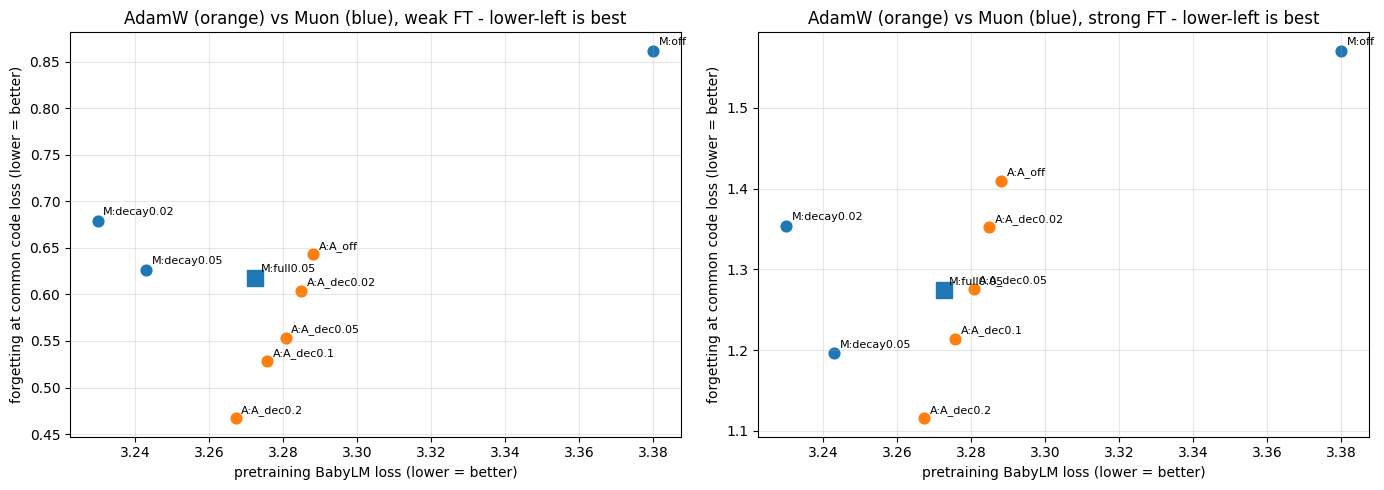

저장: /kaggle/working/exp_e2


In [8]:
# ============ 셀 7: AdamW 결과, ρ 추천, E1(Muon)과 통합 비교 ============
import matplotlib.pyplot as plt
df = pd.DataFrame(ROWS)
print('재현 확인 — A_off 망각 (L1 기록: 약 0.9636 / 강 1.8473):',
      {st: round(df[(df.strength == st) & (df.model == 'A_off')].forgetting.mean(), 4) for st in ['weak', 'strong']})

TARGET_A = {}; df['matched_forgetting'] = np.nan
for st in ['weak', 'strong']:
    sub = df[df.strength == st]
    TARGET_A[st] = max(min(p['code'] for p in CURVES[f'{st}|{r.seed}|{r.model}']) for r in sub.itertuples())
    for i, r in sub.iterrows():
        df.loc[i, 'matched_forgetting'] = baby_at(CURVES[f'{st}|{r.seed}|{r.model}'], TARGET_A[st]) - r.baby_before
df.to_csv(f'{OUT}/ft_results_final.csv', index=False)
COLS = ['code_after', 'forgetting', 'matched_forgetting', 'baby_acc_drop', 'blimp_after', 'blimp_drop',
        'ft_int4_baby_inc', 'delta_rel', 'dir_curv', 'quad_pred', 'actual_inc', 'cka_last']
print(f'\n===== AdamW 파인튜닝 후 (seed 평균) | 같은 지점: 약 {TARGET_A["weak"]:.3f}, 강 {TARGET_A["strong"]:.3f} =====')
display(df.groupby(['strength', 'model'], sort=False)[COLS].mean().round(4))

print('\n===== A_off 대비 (같은 seed 짝, 양수 = 더 좋음) =====')
REC = {}
for st in ['weak', 'strong']:
    a = df[(df.strength == st) & (df.model == 'A_off')].set_index('seed').sort_index()
    print(f'\n[{st}]')
    for key in A_KEYS[1:]:
        b = df[(df.strength == st) & (df.model == key)].set_index('seed').sort_index()
        red = 1 - b.matched_forgetting.mean() / a.matched_forgetting.mean()
        dcode = (a.code_after - b.code_after).mean()
        REC.setdefault(key, []).append((red, dcode))
        print(f'  {key:10s} 같은 지점 망각 {red*100:+5.1f}% ({int(((a.matched_forgetting - b.matched_forgetting) > 0).sum())}/3) | '
              f'코드 loss 차 {dcode:+.4f} | BLiMP 하락 차 {(a.blimp_drop - b.blimp_drop).mean()*100:+.2f}%p | '
              f'INT4(파인튜닝 후) 차 {(a.ft_int4_baby_inc - b.ft_int4_baby_inc).mean():+.3f}')

ok = [k for k in A_KEYS[1:] if PRE[k]['baby_loss'] <= PRE['A_off']['baby_loss'] + 0.003
      and min(d for _, d in REC[k]) >= -0.02]
best = max(ok, key=lambda k: np.mean([r for r, _ in REC[k]])) if ok else None
print(f'\n→ AdamW decay SAM 추천 ρ: {best}  (기준: 사전학습 손해 없음 + 코드 학습 손해 0.02 이내 + 망각 감소 최대)')

try:
    C_M = json.load(open(find_input('exp_e1', 'ft_curves.json')))
    P_M = json.load(open(find_input('exp_e1', 'pretrain_metrics.json')))
    D_M = pd.read_csv(find_input('exp_e1', 'ft_results_final.csv'))
except AssertionError as e:
    C_M = None; print('\n※ E1 결과 없음 → 통합 비교 건너뜀:', e)

if C_M:
    M_KEYS = ['off', 'decay0.02', 'decay0.05', 'full0.05']
    M_COST = {'off': 1.00, 'decay0.02': 1.26, 'decay0.05': 1.26, 'full0.05': 2.27}
    ALL = [('AdamW', k, CURVES, PRE[k], COST[k], 'A_off') for k in A_KEYS] + \
          [('Muon', k, C_M, P_M[k], M_COST[k], 'off') for k in M_KEYS]
    print('\n\n===== AdamW + Muon 통합 비교 (모든 모델이 도달한 같은 코드 loss 지점) =====')
    print('비용은 각 옵티마이저의 SAM 없음 대비. 옵티마이저 간 실제 시간은 T1 참고 (AdamW가 step당 약 1.5배 빠름)')
    out = []
    for st in ['weak', 'strong']:
        tgt = max(min(p['code'] for p in C[f'{st}|{s}|{k}']) for _, k, C, *_ in ALL for s in CFG['ft_seeds'])
        mf = {k: np.array([baby_at(C[f'{st}|{s}|{k}'], tgt) - C[f'{st}|{s}|{k}'][0]['baby'] for s in CFG['ft_seeds']])
              for _, k, C, *_ in ALL}
        print(f'\n[{st}] 공통 기준 코드 loss = {tgt:.3f}')
        for opt_name, k, C, P, cost, base in ALL:
            code_after = np.mean([C[f'{st}|{s}|{k}'][-1]['code'] for s in CFG['ft_seeds']])
            red = 1 - mf[k].mean() / mf[base].mean()
            src = df if opt_name == 'AdamW' else D_M
            blimp_after = src[(src.strength == st) & (src.model == k)].blimp_after.mean()
            int4_after = src[(src.strength == st) & (src.model == k)].ft_int4_baby_inc.mean()
            out.append(dict(strength=st, optimizer=opt_name, model=k, cost=cost, pre_loss=P['baby_loss'],
                            pre_blimp=P['blimp_acc'], pre_int4=P['int4_baby_inc'], code_after=code_after,
                            matched_forgetting=mf[k].mean(), reduction_vs_own_off=red,
                            blimp_after=blimp_after, ft_int4=int4_after))
            print(f'  {opt_name:5s} {k:10s} 비용 {cost:.2f} | 사전 loss {P["baby_loss"]:.4f} | BLiMP {P["blimp_acc"]*100:.1f}→{blimp_after*100:.1f}% | '
                  f'코드 후 {code_after:.3f} | 같은 지점 망각 {mf[k].mean():.4f} (자기 off 대비 {red*100:+.1f}%) | '
                  f'INT4 사전 +{P["int4_baby_inc"]:.3f} / 파인튜닝 후 +{int4_after:.3f}')
    comb = pd.DataFrame(out); comb.to_csv(f'{OUT}/combined_adamw_muon.csv', index=False)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, st in zip(axes, ['weak', 'strong']):
        c = comb[comb.strength == st]
        for r in c.itertuples():
            ax.scatter(r.pre_loss, r.matched_forgetting, s=60 + 60 * (r.cost > 2),
                       color='tab:orange' if r.optimizer == 'AdamW' else 'tab:blue', marker='s' if 'full' in r.model else 'o')
            ax.annotate(f'{r.optimizer[0]}:{r.model}', (r.pre_loss, r.matched_forgetting), textcoords='offset points', xytext=(4, 4), fontsize=8)
        ax.set_xlabel('pretraining BabyLM loss (lower = better)'); ax.set_ylabel('forgetting at common code loss (lower = better)')
        ax.set_title(f'AdamW (orange) vs Muon (blue), {st} FT - lower-left is best'); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(f'{OUT}/adamw_vs_muon.png', dpi=150); plt.show()
print('저장:', OUT)